In [1]:
print("Hello, Python!")

Hello, Python!


In [20]:
import pandas as pd

df = pd.read_csv("sales_data_analysis_dataset.csv")

df.head()

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Sales_Channel,Region,City,Product_ID,Product_Name,Category,Quantity,Unit_Price,Discount,Sales,Profit
0,ORD-00364,2024-01-01,2024-01-02,CUST-0311,Corporate,Online,East,Bhubaneswar,P006,Desk Lamp,Furniture,7,28.71,0.00,200.97,66.31
1,ORD-00336,2024-01-02,2024-01-09,CUST-0019,Corporate,Partner,West,Surat,P001,Wireless Mouse,Accessories,6,16.88,0.20,81.02,31.14
2,ORD-00998,2024-01-03,2024-01-10,CUST-0102,Small Business,Retail Store,East,Guwahati,P009,Printer,Technology,1,170.60,0.25,127.95,25.40
3,ORD-00671,2024-01-04,2024-01-07,CUST-0214,Corporate,Retail Store,East,Kolkata,P006,Desk Lamp,Furniture,4,30.55,0.20,97.76,28.74
4,ORD-00643,2024-01-05,2024-01-06,CUST-0247,Corporate,Online,North,Jaipur,P004,Office Chair,Furniture,8,147.72,0.10,1063.58,212.20


In [ ]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Rows and columns: (1200, 16)

Column names:
['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID', 'Customer_Segment', 'Sales_Channel', 'Region', 'City', 'Product_ID', 'Product_Name', 'Category', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit']

Data types:
Order_ID             object
Order_Date           object
Ship_Date            object
Customer_ID          object
Customer_Segment     object
Sales_Channel        object
Region               object
City                 object
Product_ID           object
Product_Name         object
Category             object
Quantity              int64
Unit_Price          float64
Discount            float64
Sales               float64
Profit              float64
dtype: object


In [22]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset size: (1200, 16)

Column names:
['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID', 'Customer_Segment', 'Sales_Channel', 'Region', 'City', 'Product_ID', 'Product_Name', 'Category', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit']

Data types:
Order_ID             object
Order_Date           object
Ship_Date            object
Customer_ID          object
Customer_Segment     object
Sales_Channel        object
Region               object
City                 object
Product_ID           object
Product_Name         object
Category             object
Quantity              int64
Unit_Price          float64
Discount            float64
Sales               float64
Profit              float64
dtype: object


In [23]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Order_ID            0
Order_Date          0
Ship_Date           0
Customer_ID         0
Customer_Segment    0
Sales_Channel       0
Region              0
City                0
Product_ID          0
Product_Name        0
Category            0
Quantity            0
Unit_Price          0
Discount            0
Sales               0
Profit              0
dtype: int64

Duplicate rows: 0


In [24]:
# Convert date columns to datetime
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"])

# Check the updated data types
print(df[["Order_Date", "Ship_Date"]].dtypes)

# Display a few dates
df[["Order_Date", "Ship_Date"]].head()

Order_Date    datetime64[ns]
Ship_Date     datetime64[ns]
dtype: object


,Order_Date,Ship_Date
0,2024-01-01,2024-01-02
1,2024-01-02,2024-01-09
2,2024-01-03,2024-01-10
3,2024-01-04,2024-01-07
4,2024-01-05,2024-01-06


In [25]:
# Calculate expected sales before discount
df["Calculated_Sales"] = df["Quantity"] * df["Unit_Price"]

# Calculate the difference from recorded sales
df["Sales_Difference"] = (
    df["Sales"] - df["Calculated_Sales"]
).round(2)

# Summarize the comparison
print("Rows where Sales differs from Quantity × Unit_Price:",
      (df["Sales_Difference"].abs() > 0.01).sum())

print("\nSample comparison:")
df[[
    "Quantity",
    "Unit_Price",
    "Discount",
    "Sales",
    "Calculated_Sales",
    "Sales_Difference"
]].head(10)

Rows where Sales differs from Quantity × Unit_Price: 855

Sample comparison:


,Quantity,Unit_Price,Discount,Sales,Calculated_Sales,Sales_Difference
0,7,28.71,0.00,200.97,200.97,0.00
1,6,16.88,0.20,81.02,101.28,-20.26
2,1,170.60,0.25,127.95,170.60,-42.65
3,4,30.55,0.20,97.76,122.20,-24.44
4,8,147.72,0.10,1063.58,1181.76,-118.18
5,8,347.74,0.00,2781.92,2781.92,0.00
6,3,17.45,0.05,49.73,52.35,-2.62
7,8,5.83,0.25,34.98,46.64,-11.66
8,2,28.53,0.15,48.50,57.06,-8.56
9,3,6.55,0.15,16.70,19.65,-2.95


In [26]:
# Calculate expected sales after discount
df["Expected_Sales"] = (
    df["Quantity"]
    * df["Unit_Price"]
    * (1 - df["Discount"])
).round(2)

# Compare expected sales with recorded sales
df["Discount_Difference"] = (
    df["Sales"] - df["Expected_Sales"]
).round(2)

mismatches = (
    df["Discount_Difference"].abs() > 0.02
).sum()

print("Rows not matching the discount formula:", mismatches)

print("\nSample verification:")
df[[
    "Quantity",
    "Unit_Price",
    "Discount",
    "Sales",
    "Expected_Sales",
    "Discount_Difference"
]].head(10)

Rows not matching the discount formula: 0

Sample verification:


,Quantity,Unit_Price,Discount,Sales,Expected_Sales,Discount_Difference
0,7,28.71,0.00,200.97,200.97,0.0
1,6,16.88,0.20,81.02,81.02,0.0
2,1,170.60,0.25,127.95,127.95,0.0
3,4,30.55,0.20,97.76,97.76,0.0
4,8,147.72,0.10,1063.58,1063.58,0.0
5,8,347.74,0.00,2781.92,2781.92,0.0
6,3,17.45,0.05,49.73,49.73,0.0
7,8,5.83,0.25,34.98,34.98,0.0
8,2,28.53,0.15,48.50,48.50,0.0
9,3,6.55,0.15,16.70,16.70,0.0


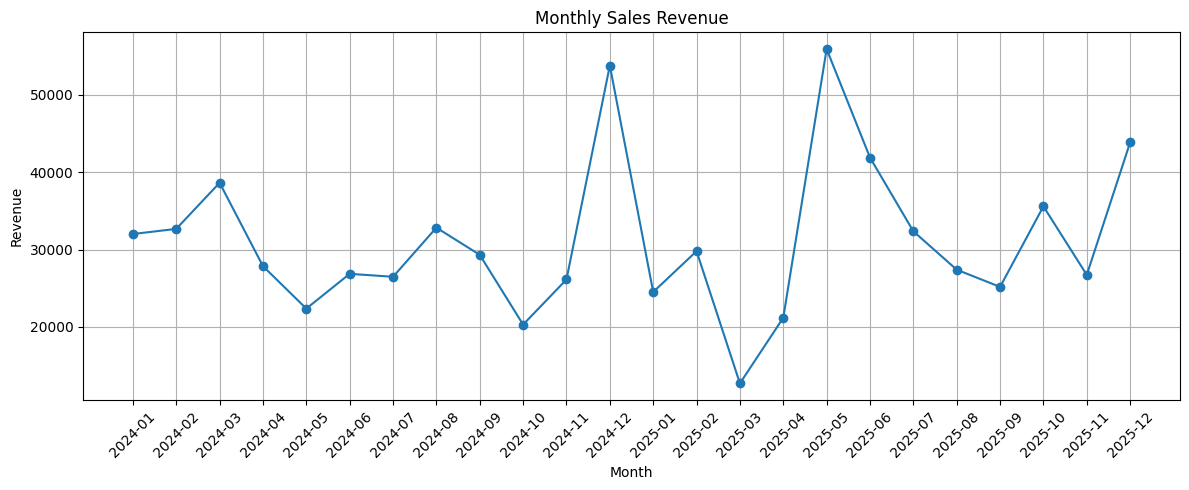

In [27]:

import matplotlib.pyplot as plt

# Calculate monthly revenue
monthly_sales = (
    df.assign(
        Sales_Month=df["Order_Date"].dt.to_period("M").astype(str)
    )
    .groupby("Sales_Month", as_index=False)["Sales"]
    .sum()
)

# Create the line chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Sales_Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [28]:

# Find the month with the highest revenue
best_month = monthly_sales.loc[monthly_sales["Sales"].idxmax()]

# Find the month with the lowest revenue
worst_month = monthly_sales.loc[monthly_sales["Sales"].idxmin()]

print("Highest Revenue Month")
print("Month:", best_month["Sales_Month"])
print("Revenue:", round(best_month["Sales"], 2))

print("\nLowest Revenue Month")
print("Month:", worst_month["Sales_Month"])
print("Revenue:", round(worst_month["Sales"], 2))


Highest Revenue Month
Month: 2025-05
Revenue: 55935.13

Lowest Revenue Month
Month: 2025-03
Revenue: 12692.76


In [29]:

# Calculate monthly profit
monthly_profit = (
    df.assign(
        Sales_Month=df["Order_Date"].dt.to_period("M").astype(str)
    )
    .groupby("Sales_Month", as_index=False)["Profit"]
    .sum()
)

# Find highest and lowest profit months
best_profit_month = monthly_profit.loc[
    monthly_profit["Profit"].idxmax()
]

worst_profit_month = monthly_profit.loc[
    monthly_profit["Profit"].idxmin()
]

print("Highest Profit Month")
print("Month:", best_profit_month["Sales_Month"])
print("Profit:", round(best_profit_month["Profit"], 2))

print("\nLowest Profit Month")
print("Month:", worst_profit_month["Sales_Month"])
print("Profit:", round(worst_profit_month["Profit"], 2))


Highest Profit Month
Month: 2024-12
Profit: 16463.66

Lowest Profit Month
Month: 2025-03
Profit: 3446.26


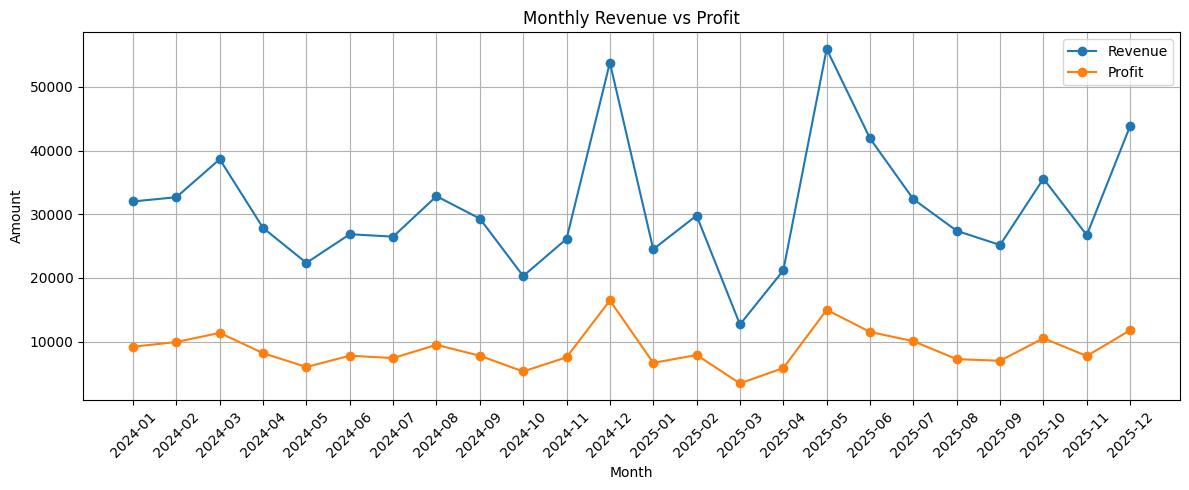

In [30]:

# Combine monthly revenue and profit
monthly_performance = (
    df.assign(
        Sales_Month=df["Order_Date"].dt.to_period("M").astype(str)
    )
    .groupby("Sales_Month", as_index=False)
    .agg(
        Revenue=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

# Plot revenue and profit
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_performance["Sales_Month"],
    monthly_performance["Revenue"],
    marker="o",
    label="Revenue"
)

plt.plot(
    monthly_performance["Sales_Month"],
    monthly_performance["Profit"],
    marker="o",
    label="Profit"
)

plt.title("Monthly Revenue vs Profit")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [31]:

# Calculate monthly profit margin
monthly_performance["Profit_Margin"] = (
    monthly_performance["Profit"]
    / monthly_performance["Revenue"]
    * 100
).round(2)

# Display monthly results
print(
    monthly_performance[
        ["Sales_Month", "Revenue", "Profit", "Profit_Margin"]
    ].to_string(index=False)
)


Sales_Month  Revenue   Profit  Profit_Margin
    2024-01 32010.09  9191.94          28.72
    2024-02 32674.38  9939.25          30.42
    2024-03 38636.30 11373.71          29.44
    2024-04 27853.42  8185.73          29.39
    2024-05 22361.17  6012.93          26.89
    2024-06 26861.02  7788.24          28.99
    2024-07 26477.79  7419.66          28.02
    2024-08 32831.86  9495.44          28.92
    2024-09 29317.61  7780.36          26.54
    2024-10 20291.52  5316.36          26.20
    2024-11 26128.82  7539.56          28.86
    2024-12 53800.85 16463.66          30.60
    2025-01 24507.64  6667.75          27.21
    2025-02 29791.36  7891.48          26.49
    2025-03 12692.76  3446.26          27.15
    2025-04 21174.77  5848.33          27.62
    2025-05 55935.13 14987.21          26.79
    2025-06 41900.61 11519.87          27.49
    2025-07 32363.24 10067.61          31.11
    2025-08 27395.76  7244.95          26.45
    2025-09 25169.15  6996.94          27.80
    2025-1

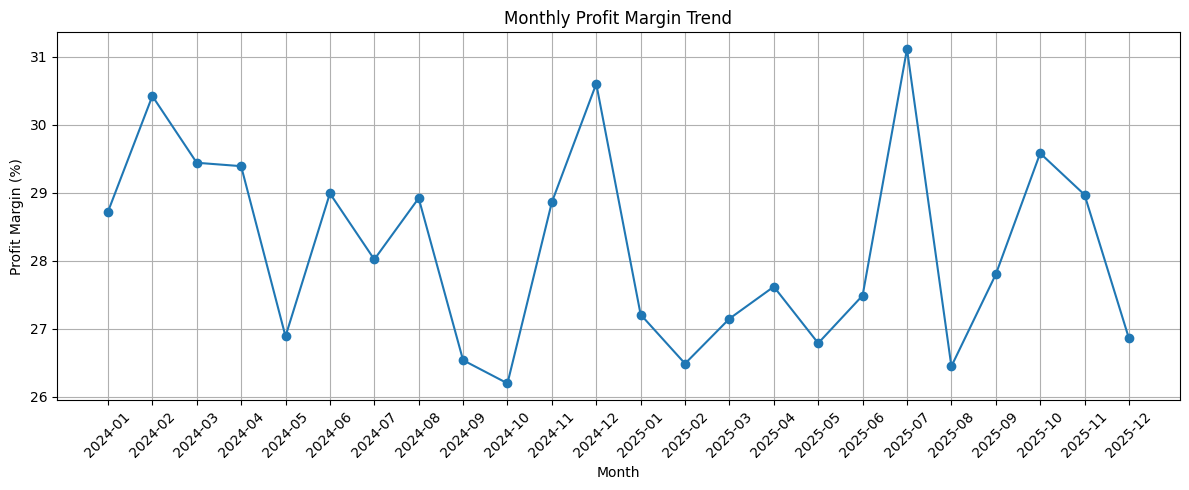

In [32]:

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_performance["Sales_Month"],
    monthly_performance["Profit_Margin"],
    marker="o"
)

plt.title("Monthly Profit Margin Trend")
plt.xlabel("Month")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [33]:

# Analyze sales performance by category
category_analysis = (
    df.groupby("Category", as_index=False)
    .agg(
        Revenue=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transactions=("Order_ID", "nunique")
    )
)

# Calculate profit margin
category_analysis["Profit_Margin"] = (
    category_analysis["Profit"]
    / category_analysis["Revenue"]
    * 100
).round(2)

# Sort categories by revenue
category_analysis = category_analysis.sort_values(
    by="Revenue",
    ascending=False
)

print(category_analysis.round(2).to_string(index=False))


       Category   Revenue    Profit  Units_Sold  Transactions  Profit_Margin
     Technology 463117.51 130632.97        1307           300          28.21
      Furniture 184039.72  52453.90        1215           296          28.50
Office Supplies  52192.73  14931.10        1286           284          28.61
    Accessories  46996.05  13208.67        1457           320          28.11


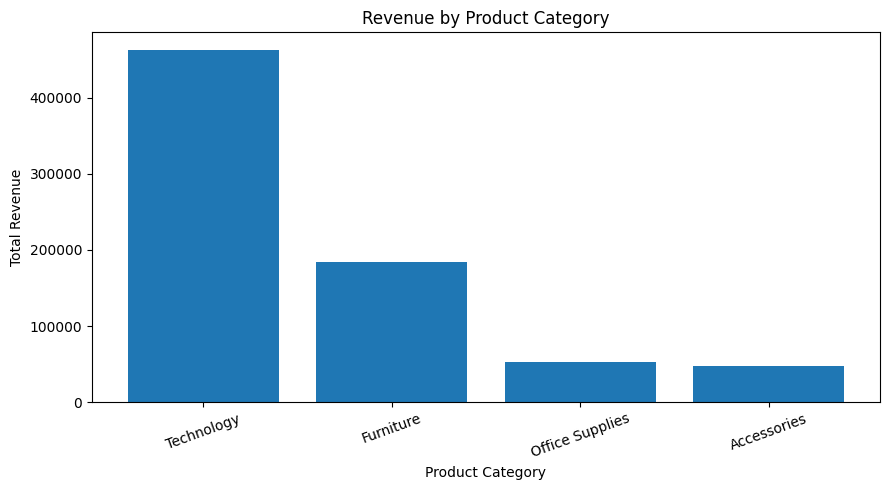

In [34]:

plt.figure(figsize=(9, 5))

plt.bar(
    category_analysis["Category"],
    category_analysis["Revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


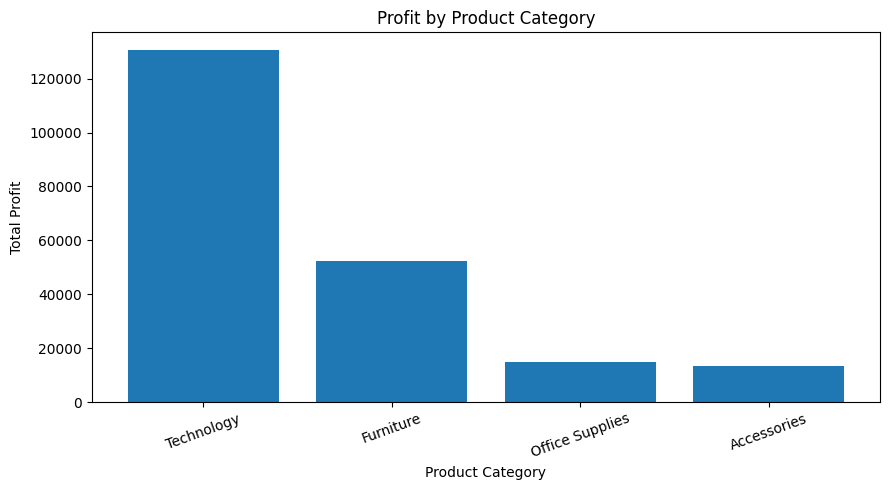

In [35]:

plt.figure(figsize=(9, 5))

plt.bar(
    category_analysis["Category"],
    category_analysis["Profit"]
)

plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [36]:

# Analyze sales performance by region
region_analysis = (
    df.groupby("Region", as_index=False)
    .agg(
        Revenue=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transactions=("Order_ID", "nunique")
    )
)

# Calculate profit margin
region_analysis["Profit_Margin"] = (
    region_analysis["Profit"]
    / region_analysis["Revenue"]
    * 100
).round(2)

# Sort regions by revenue
region_analysis = region_analysis.sort_values(
    by="Revenue",
    ascending=False
)

print(region_analysis.round(2).to_string(index=False))


Region   Revenue   Profit  Units_Sold  Transactions  Profit_Margin
  East 214967.86 62177.31        1349           306          28.92
 South 212983.54 58682.68        1381           313          27.55
  West 159936.86 44999.86        1234           298          28.14
 North 158457.75 45366.79        1301           283          28.63


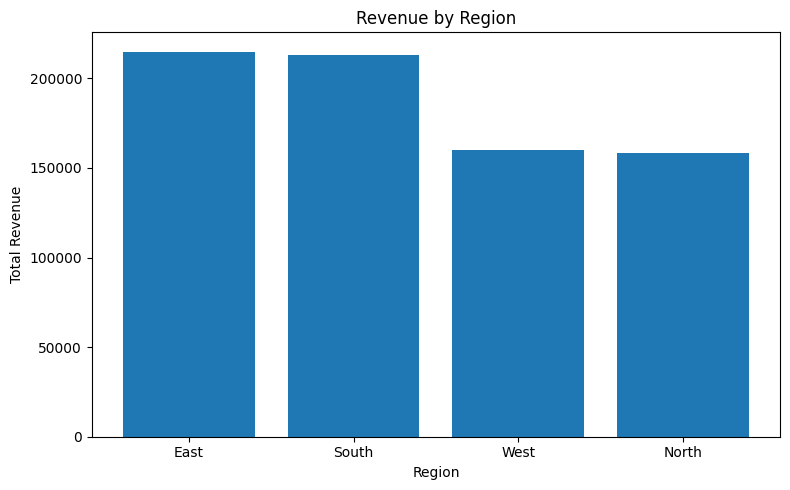

In [37]:

plt.figure(figsize=(8, 5))

plt.bar(
    region_analysis["Region"],
    region_analysis["Revenue"]
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


In [38]:

# Analyze customer segment performance
segment_analysis = (
    df.groupby("Customer_Segment", as_index=False)
    .agg(
        Revenue=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transactions=("Order_ID", "nunique")
    )
)

# Calculate profit margin
segment_analysis["Profit_Margin"] = (
    segment_analysis["Profit"]
    / segment_analysis["Revenue"]
    * 100
).round(2)

# Sort by revenue
segment_analysis = segment_analysis.sort_values(
    by="Revenue",
    ascending=False
)

print(segment_analysis.round(2).to_string(index=False))


Customer_Segment   Revenue   Profit  Units_Sold  Transactions  Profit_Margin
  Small Business 292322.32 82445.45        1985           445          28.20
        Consumer 268553.94 78104.81        1631           374          29.08
       Corporate 185469.75 50676.38        1649           381          27.32


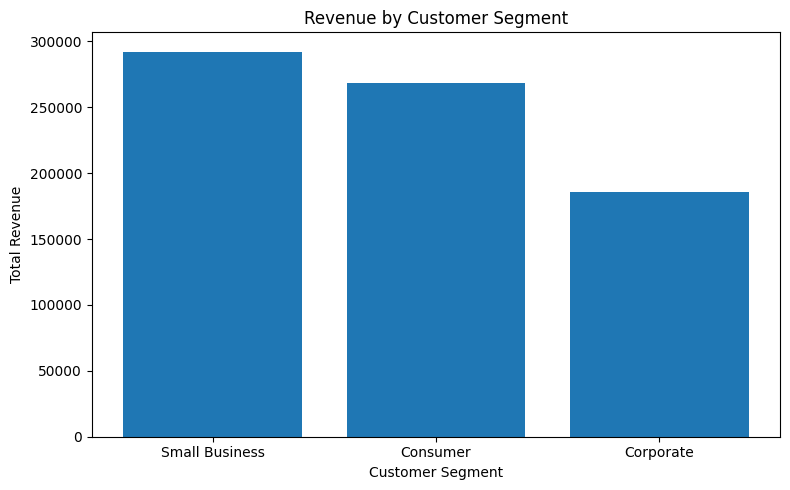

In [39]:

plt.figure(figsize=(8, 5))

plt.bar(
    segment_analysis["Customer_Segment"],
    segment_analysis["Revenue"]
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


In [40]:

# Analyze product performance
product_analysis = (
    df.groupby(["Product_ID", "Product_Name"], as_index=False)
    .agg(
        Revenue=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transactions=("Order_ID", "nunique")
    )
)

# Select the top 10 products by revenue
top_10_products = product_analysis.sort_values(
    by="Revenue",
    ascending=False
).head(10)

print(top_10_products.round(2).to_string(index=False))


Product_ID        Product_Name   Revenue   Profit  Units_Sold  Transactions
      P007              Laptop 297157.87 84442.60         388            92
      P005       Standing Desk 121164.64 34732.50         413            96
      P008             Monitor  98483.14 28012.25         495           112
      P009             Printer  67476.50 18178.12         424            96
      P004        Office Chair  52242.47 14702.01         389           103
      P011      Filing Cabinet  46829.21 13431.63         468           104
      P002 Mechanical Keyboard  24065.60  6765.36         474           109
      P003           USB-C Hub  15300.68  4167.86         520           109
      P006           Desk Lamp  10632.61  3019.39         413            97
      P001      Wireless Mouse   7629.77  2275.45         463           102


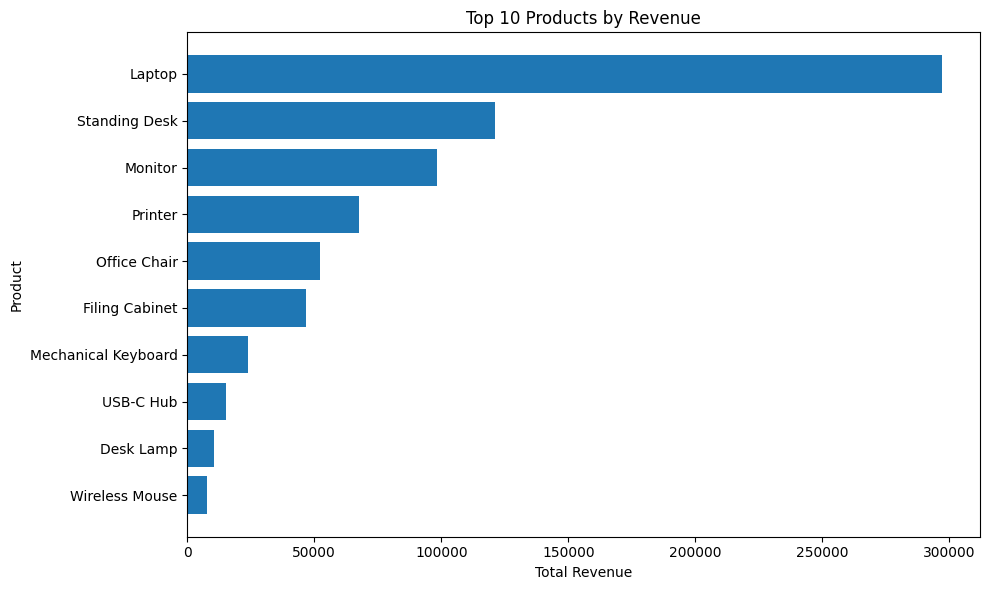

In [41]:

top_10_chart = top_10_products.sort_values(
    by="Revenue",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_chart["Product_Name"],
    top_10_chart["Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()



In [42]:

# Analyze customer performance
customer_analysis = (
    df.groupby("Customer_ID", as_index=False)
    .agg(
        Revenue=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
)

# Find the top 10 customers by revenue
top_10_customers = customer_analysis.sort_values(
    by="Revenue",
    ascending=False
).head(10)

print(top_10_customers.round(2).to_string(index=False))


Customer_ID  Revenue  Profit  Orders  Units_Sold
  CUST-0248 10705.68 2727.58       4          18
  CUST-0022 10171.64 2164.02       4          20
  CUST-0176  9582.63 2923.36       7          35
  CUST-0001  9404.10 3151.33       5          36
  CUST-0049  9396.75 2482.98       6          36
  CUST-0069  9067.37 3039.42       6          29
  CUST-0088  8731.95 2509.12       8          39
  CUST-0111  8499.47 2578.49       5          29
  CUST-0162  8230.04 2266.80       7          38
  CUST-0078  7966.83 1926.20       3          22


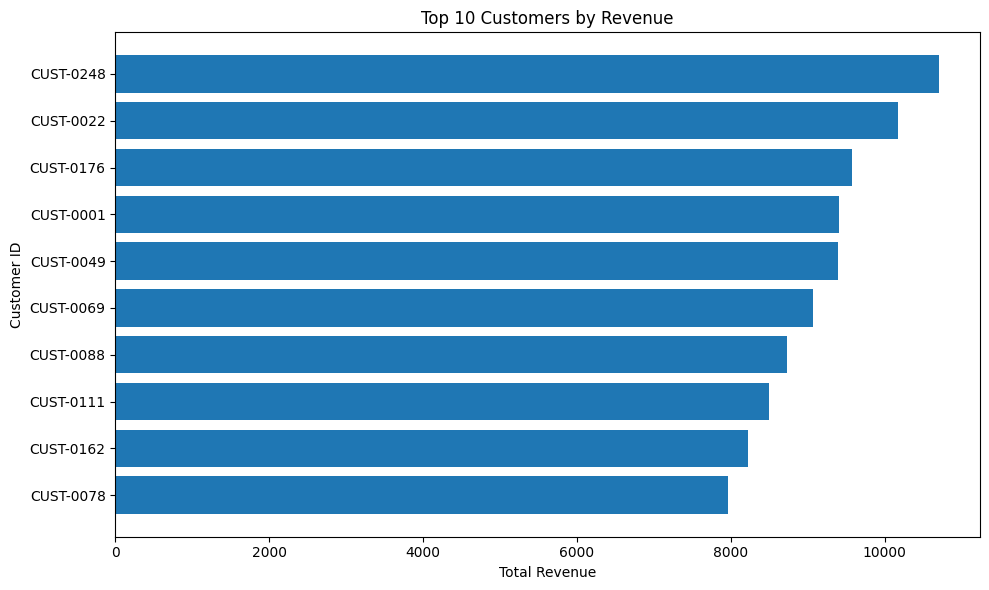

In [43]:

top_customers_chart = top_10_customers.sort_values(
    by="Revenue",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_customers_chart["Customer_ID"],
    top_customers_chart["Revenue"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


In [44]:

# Group sales by discount level
discount_analysis = (
    df.groupby("Discount", as_index=False)
    .agg(
        Revenue=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
)

# Calculate profit margin
discount_analysis["Profit_Margin"] = (
    discount_analysis["Profit"]
    / discount_analysis["Revenue"]
    * 100
).round(2)

print(discount_analysis.round(2).to_string(index=False))


 Discount   Revenue   Profit  Orders  Units_Sold  Profit_Margin
     0.00 227791.87 69302.73     345        1474          30.42
     0.05 109596.42 30523.47     168         751          27.85
     0.10 111625.10 31451.39     178         838          28.18
     0.15 110936.64 29595.34     172         751          26.68
     0.20  91267.32 24959.66     174         746          27.35
     0.25  95128.66 25394.05     163         705          26.69


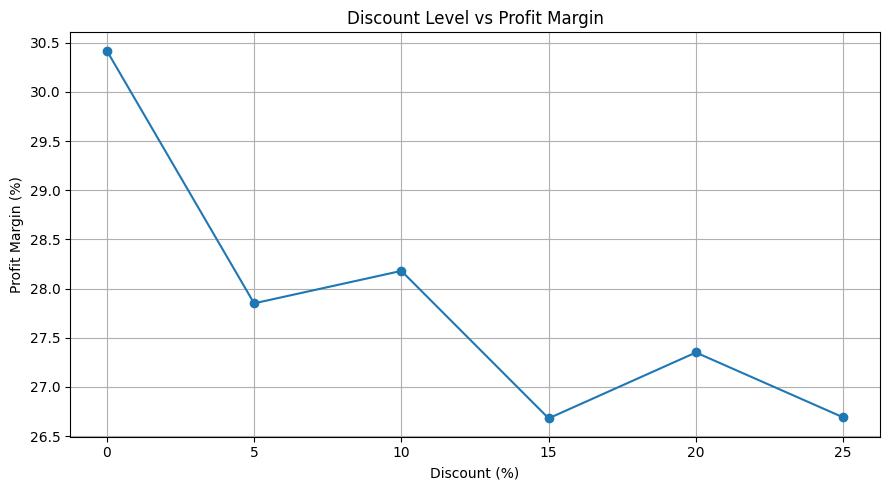

In [45]:

plt.figure(figsize=(9, 5))

plt.plot(
    discount_analysis["Discount"] * 100,
    discount_analysis["Profit_Margin"],
    marker="o"
)

plt.title("Discount Level vs Profit Margin")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.xticks(discount_analysis["Discount"] * 100)
plt.grid(True)
plt.tight_layout()
plt.show()


In [46]:

# Calculate shipping time in days
df["Shipping_Days"] = (
    df["Ship_Date"] - df["Order_Date"]
).dt.days

# Overall shipping statistics
print("Average Shipping Days:", round(df["Shipping_Days"].mean(), 2))
print("Fastest Shipping Days:", df["Shipping_Days"].min())
print("Slowest Shipping Days:", df["Shipping_Days"].max())

# Show sample orders
print("\nSample Shipping Data:")
print(
    df[["Order_ID", "Order_Date", "Ship_Date", "Shipping_Days"]]
    .head(10)
    .to_string(index=False)
)


Average Shipping Days: 3.95
Fastest Shipping Days: 1
Slowest Shipping Days: 7

Sample Shipping Data:
 Order_ID Order_Date  Ship_Date  Shipping_Days
ORD-00364 2024-01-01 2024-01-02              1
ORD-00336 2024-01-02 2024-01-09              7
ORD-00998 2024-01-03 2024-01-10              7
ORD-00671 2024-01-04 2024-01-07              3
ORD-00643 2024-01-05 2024-01-06              1
ORD-00042 2024-01-06 2024-01-09              3
ORD-00926 2024-01-06 2024-01-11              5
ORD-00296 2024-01-07 2024-01-13              6
ORD-00130 2024-01-07 2024-01-09              2
ORD-00267 2024-01-07 2024-01-10              3


In [47]:

# Calculate average shipping time by region
shipping_by_region = (
    df.groupby("Region", as_index=False)
    .agg(
        Average_Shipping_Days=("Shipping_Days", "mean"),
        Orders=("Order_ID", "nunique")
    )
)

shipping_by_region["Average_Shipping_Days"] = (
    shipping_by_region["Average_Shipping_Days"].round(2)
)

shipping_by_region = shipping_by_region.sort_values(
    by="Average_Shipping_Days",
    ascending=False
)

print(shipping_by_region.to_string(index=False))


Region  Average_Shipping_Days  Orders
 North                   3.98     283
  East                   3.97     306
  West                   3.97     298
 South                   3.88     313


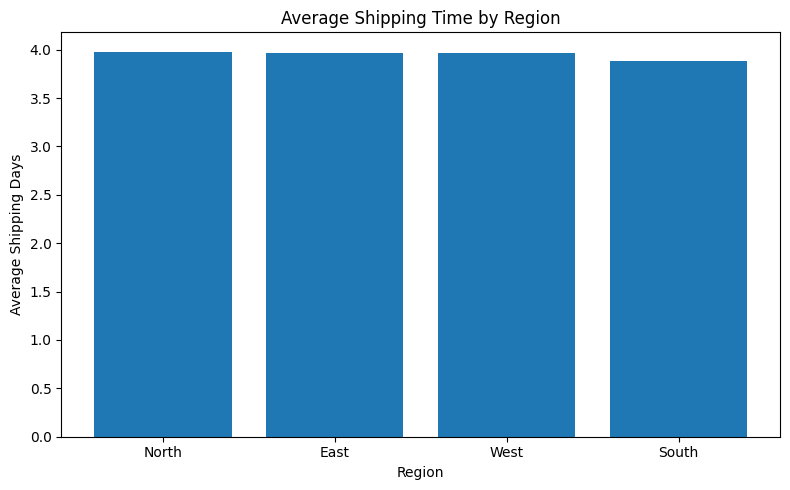

In [48]:

plt.figure(figsize=(8, 5))

plt.bar(
    shipping_by_region["Region"],
    shipping_by_region["Average_Shipping_Days"]
)

plt.title("Average Shipping Time by Region")
plt.xlabel("Region")
plt.ylabel("Average Shipping Days")
plt.tight_layout()
plt.show()


In [49]:

# Check for negative or zero values
print("Sales less than or equal to zero:",
      (df["Sales"] <= 0).sum())

print("Profit less than zero:",
      (df["Profit"] < 0).sum())

print("Quantity less than or equal to zero:",
      (df["Quantity"] <= 0).sum())

print("Unit price less than or equal to zero:",
      (df["Unit_Price"] <= 0).sum())

print("Negative shipping days:",
      (df["Shipping_Days"] < 0).sum())

# Display descriptive statistics
print("\nNumerical Summary:")
print(df[[
    "Quantity", "Unit_Price", "Discount",
    "Sales", "Profit", "Shipping_Days"
]].describe().round(2))


Sales less than or equal to zero: 0
Profit less than zero: 0
Quantity less than or equal to zero: 0
Unit price less than or equal to zero: 0
Negative shipping days: 0

Numerical Summary:
       Quantity  Unit_Price  Discount    Sales   Profit  Shipping_Days
count   1200.00     1200.00   1200.00  1200.00  1200.00        1200.00
mean       4.39      163.70      0.11   621.96   176.02           3.95
std        2.29      225.83      0.09  1002.38   300.95           2.00
min        1.00        5.52      0.00     4.17     0.89           1.00
25%        2.00       26.54      0.00    77.80    20.23           2.00
50%        4.00      101.79      0.10   216.29    62.01           4.00
75%        6.00      198.02      0.20   732.42   199.88           6.00
max        8.00      950.45      0.25  6538.88  2742.38           7.00
